# Fixed nominal wage, cohort by cohort

The fixed-wage counterpart of `demand_shock_cohorts.ipynb` and `A_shock_cohorts.ipynb`.
Everything about the production side is unchanged — same calibration, same steady state, same
commitment structure, deliveries at $t$ still locked at $y_i^{ss}$ for every producer with
$\tau_i>t$.  One equation changes.

## What changes

The two cohort notebooks impose labour-market clearing at every date,

$$\frac{W_t}{P_t}=\chi L_t^{\eta}C_t^{\gamma}\qquad\text{(flexible wage)} .$$

Here that is replaced by a **fixed nominal wage**

$$W_t=W^{ss}\qquad\text{(fixed wage)} ,$$

and employment becomes whatever producers demand at that wage,
$L_t=\sum_i y_{i,t+\tau_i}/(\zeta_iA_t)$.  The household is then *off* its labour-supply
schedule: it works what it is asked to work.  Section 5 measures how far off, since that wedge
is the entire content of the friction.

Because $W^{ss}$ is also the market-clearing wage in steady state, the two models share the
same steady state and the no-shock path is identical — the friction only bites after a shock.

## Why this version exists

In the flexible-wage cohort notebooks the nominal interest rate is **exactly neutral**: the
commitment is in quantities rather than in nominal prices, and every relative price reduces to
$\omega_{t-\tau_i}\prod(1+r_j)/(\zeta_iA)$, which contains only the real rate.  Section 4
re-runs that test here and it fails — with the wage fixed, the price level is no longer free to
move with the wage, so the rate has traction.  That is what makes an optimal-rate question
well-posed, and this notebook is the model `optimal_rate.ipynb` is actually solving.

## Solving it

Unknowns are the output path alone: $W_t$ is given, the free producers' prices follow from
$W_{t-\tau_i}$ and the rate path, $P_t$ from the CES index, quantities from demand, and $L_t$ is
residual.  The Euler equation supplies one equation per date.  (The code below carries a
$\phi$ switch — $\phi=1$ fixed wage, $\phi=0$ flexible — so that the two models can be run
against each other in one place; $\phi=1$ is the model of this notebook.)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import root, least_squares

pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 40)

# the least-squares search probes rate paths that violate the committed-goods floor before
# backing off; those trial points overflow harmlessly, so silence the numpy chatter
_ = np.seterr(over='ignore', divide='ignore', invalid='ignore')

/Users/samuelzhao/anaconda3/lib/python3.10/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


## 1. Calibration, steady state, and the model

In [2]:
INVENTORY_TO_COGS_SCALING = 36.5
NOMINAL_INTEREST_RATE     = 0.01

sigma = 5.0; gamma = 2.0; eta = 2.0; chi = 1.0
mu      = 1.0        # perfectly competitive: price = marginal cost.
                     # was sigma/(sigma-1) = 1.25, a monopolistic-competition markup.
beta    = 1 / (1.0 + NOMINAL_INTEREST_RATE)
beta1   = 1 / (1.0 + NOMINAL_INTEREST_RATE * np.exp(30 / (INVENTORY_TO_COGS_SCALING * 0.9)))
beta_hh = beta
rho     = 1 / beta - 1

data = pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True)
data_tau = data['invtCogsRatio'] * INVENTORY_TO_COGS_SCALING / (30 * 0.1)

c_list = np.linspace(0, 0.99, 1000); tau_diff = np.zeros(1000)
for i, cv in enumerate(c_list):
    if beta * cv <= 1e-10:
        tau_diff[i] = np.inf; continue
    Nn = -(data_tau) - 1 / np.log(beta * cv)
    t1 = -1 / np.log(beta * cv) - Nn;  t1[t1 < 0] = 0
    t2 = -1 / np.log(beta1 * cv) - Nn; t2[t2 < 0] = 0
    tau_diff[i] = np.mean(np.abs(t1 - t2))
c = np.min(c_list[np.where(np.abs(tau_diff - 1) == np.min(np.abs(tau_diff - 1)))[0]])

N = -data_tau - 1 / np.log(beta * c)
tau = -1 / np.log(beta * c) - N; tau[tau < 0] = 0
tf, tc = np.floor(tau), np.ceil(tau)
pc = (beta * c)**tc * (tc + N); pf = (beta * c)**tf * (tf + N)
tau[(pc - pf) > 0] = tc[(pc - pf) > 0]
tau[(pc - pf) < 0] = tf[(pc - pf) < 0]; tau[tau < 0] = 0

TVALS  = tau.astype(int).to_numpy(); N_ARRAY = np.array(N)
kappa  = c; NF = len(TVALS); TAUMAX = int(TVALS.max())
ZETA   = kappa ** TVALS * (TVALS + N_ARRAY)

T     = 30
FREE  = TVALS[None, :] <= np.arange(T)[:, None]
SMAT  = np.maximum(np.arange(T)[:, None] - TVALS[None, :], 0)   # hiring date, clipped
TPT   = np.arange(T)[:, None] + TVALS[None, :]                  # delivery date of batch t
DISC  = beta_hh ** np.arange(T)


def steady(A=1.0, W=1.0):
    z  = beta ** TVALS * ZETA * A
    At = np.sum(z ** (sigma - 1)) ** (1 / (sigma - 1))
    Lam = np.sum(z ** (sigma - 1) * beta ** TVALS)
    Th = At ** sigma / Lam
    L  = (At / (mu * chi * Th ** gamma)) ** (1 / (gamma + eta)); Y = Th * L
    p  = mu * W / z; P = np.sum(p ** (1 - sigma)) ** (1 / (1 - sigma))
    y  = (p / P) ** (-sigma) * Y
    return dict(A_til=At, Theta=Th, L=L, Y=Y, C=Y, W=W, P=P, p=p, y=y,
                l=y / (ZETA * A), omega=W / P)


SS    = steady()
S_QTY = np.array([np.sum(SS['y'][~FREE[t]] ** ((sigma - 1) / sigma)) for t in range(T)])
Y_FLR = S_QTY ** (sigma / (sigma - 1))       # committed-goods floor under output


def alloc(W, Y, i_path, A_path):
    '''Prices, quantities and employment given nominal wage, output and the rate path.'''
    pad = TAUMAX + 2
    Wx = np.r_[W, np.full(pad, SS['W'])]; Ax = np.r_[A_path, np.full(pad, A_path[-1])]
    ix = np.r_[i_path, np.full(pad, rho)]; cd = np.r_[1.0, np.cumprod(1.0 / (1.0 + ix))]
    p_f = mu * Wx[SMAT] / ((cd[np.arange(T)][:, None] / cd[SMAT]) * ZETA[None, :] * Ax[SMAT])
    Q   = np.sum(np.where(FREE, p_f ** (1 - sigma), 0.0), axis=1)
    P   = (Q / (1.0 - S_QTY * Y ** ((1 - sigma) / sigma))) ** (1 / (1 - sigma))
    y   = np.where(FREE, (p_f / P[:, None]) ** (-sigma) * Y[:, None], SS['y'][None, :])
    p   = np.where(FREE, p_f, P[:, None] * (SS['y'][None, :] / Y[:, None]) ** (-1 / sigma))
    yx  = np.vstack([y, np.tile(SS['y'], (pad, 1))])
    l   = yx[TPT, np.arange(NF)] / (ZETA * Ax[:T, None])
    return P, p, y, l, l.sum(axis=1)


_WARM = {}
def solve(i_path=None, A_path=None, xi=None, phi=1.0, key=None):
    '''phi = 0: flexible wage (policy neutral).  phi = 1: nominal wage pinned at W_ss.'''
    i_path = np.full(T, rho) if i_path is None else np.asarray(i_path, float)
    A_path = np.ones(T)      if A_path is None else np.asarray(A_path, float)
    xi     = np.zeros(T)     if xi     is None else np.asarray(xi, float)

    def resid(u):
        W = np.exp(u[:T]); Y = Y_FLR + np.exp(u[T:])
        P, _, _, _, L = alloc(W, Y, i_path, A_path)
        Px = np.r_[P, SS['P']]; Yx = np.r_[Y, SS['Y']]; xix = np.r_[xi, 0.0]
        wage = (1 - phi) * (np.log(W / P) - (np.log(chi) + eta*np.log(L) + gamma*np.log(Y))) \
             + phi * (np.log(W) - np.log(SS['W']))
        eu = (xix[:T] - gamma*np.log(Yx[:T]) - np.log(Px[:T])) \
           - (np.log(beta_hh) + np.log(1 + i_path) + xix[1:]
              - gamma*np.log(Yx[1:]) - np.log(Px[1:]))
        return np.r_[wage, eu]

    u0 = _WARM.get(key, np.r_[np.full(T, np.log(SS['W'])), np.log(SS['Y'] - Y_FLR)])
    s  = root(resid, u0, method='hybr', tol=1e-13)
    if s.success and key is not None: _WARM[key] = s.x
    W = np.exp(s.x[:T]); Y = Y_FLR + np.exp(s.x[T:])
    P, p, y, l, L = alloc(W, Y, i_path, A_path)
    return dict(W=W, Y=Y, C=Y, P=P, p=p, y=y, l=l, L=L, i=i_path, A=A_path, xi=xi, phi=phi,
                omega=W / P, ok=s.success, res=float(np.max(np.abs(s.fun))),
                pi=np.r_[np.log(P[0] / SS['P']), np.diff(np.log(P))],
                welfare=float(np.sum(DISC * np.exp(xi) *
                              (Y**(1-gamma)/(1-gamma) - chi*L**(1+eta)/(1+eta)))))


XI_D  = np.r_[-0.01, np.zeros(T - 1)]      # 1 % contractionary demand shock
A_1P  = np.r_[0.97,  np.ones(T - 1)]       # 3 % TFP hit to the batches started at t = 0
SHOCKS = {'demand shock': dict(xi=XI_D), 'TFP shock': dict(A_path=A_1P)}

print(f'kappa = {kappa:.6f}   n = {NF}   tau in [0, {TAUMAX}]   T = {T}')
print(f'SS: Y = {SS["Y"]:.6f}  L = {SS["L"]:.6f}  W/P = {SS["omega"]:.6f}')
chk = solve(phi=1.0)
print(f'no shock, phi = 1 reproduces the steady state: max|dlogY| = '
      f'{np.max(np.abs(np.log(chk["Y"]/SS["Y"]))):.2e}')

/var/folders/26/bmvk0hrd5xbgcvl_s6s42rf80000gn/T/ipykernel_71679/666129961.py:12: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data = pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True)


kappa = 0.901802   n = 269   tau in [0, 13]   T = 30
SS: Y = 11.935519  L = 0.434343  W/P = 26.875001
no shock, phi = 1 reproduces the steady state: max|dlogY| = 4.44e-16


## 2. The cohort structure is untouched

The commitment is a property of the technology, not of the wage, so the staggering is exactly
what it was in the two flexible-wage notebooks.

In [3]:
FIX  = {nm: solve(phi=1.0, key='fx' + nm, **kw) for nm, kw in SHOCKS.items()}
FLEX = {nm: solve(phi=0.0, key='fl' + nm, **kw) for nm, kw in SHOCKS.items()}

for nm, s in FIX.items():
    print(f"{nm:<13} converged = {s['ok']},  max |residual| = {s['res']:.2e}")

print('\nProducers off the steady-state quantity (fixed wage, demand shock):')
s = FIX['demand shock']
for t in range(6):
    mv = np.where(np.abs(s['y'][t] / SS['y'] - 1) > 1e-10)[0]
    print(f'   t={t}:  {len(mv):>3} producers,  taus = {sorted(set(TVALS[mv]))}')
for nm, a in {**FIX, **{'flex ' + k: v for k, v in FLEX.items()}}.items():
    assert all(np.allclose(a['y'][t][TVALS > t], SS['y'][TVALS > t]) for t in range(T)), nm
    assert all(set(TVALS[np.abs(a['y'][t] / SS['y'] - 1) > 1e-10]) <= set(range(t + 1))
               for t in range(T)), nm
print('\n   assertion passed: at every t, exactly the producers with tau <= t deviate,')
print('   under both wage assumptions.')

nosh = solve(phi=1.0, key='nosh')
print(f"\n   no shock reproduces the steady state:  max|dlogY| = "
      f"{np.max(np.abs(np.log(nosh['Y']/SS['Y']))):.2e},  "
      f"max|dlogL| = {np.max(np.abs(np.log(nosh['L']/SS['L']))):.2e}")
print(f"   the fixed wage really is fixed:        max|dlogW| = "
      f"{max(np.max(np.abs(np.log(a['W']/SS['W']))) for a in FIX.values()):.2e}")
print(f"   under a flexible wage it moves:        max|dlogW| = "
      f"{max(np.max(np.abs(np.log(a['W']/SS['W']))) for a in FLEX.values()):.2e}")

demand shock  converged = True,  max |residual| = 8.88e-16
TFP shock     converged = True,  max |residual| = 2.22e-15

Producers off the steady-state quantity (fixed wage, demand shock):
   t=0:    1 producers,  taus = [0]
   t=1:    0 producers,  taus = []
   t=2:    0 producers,  taus = []
   t=3:    0 producers,  taus = []
   t=4:    0 producers,  taus = []
   t=5:    0 producers,  taus = []

   assertion passed: at every t, exactly the producers with tau <= t deviate,
   under both wage assumptions.

   no shock reproduces the steady state:  max|dlogY| = 4.44e-16,  max|dlogL| = 4.44e-16
   the fixed wage really is fixed:        max|dlogW| = 0.00e+00
   under a flexible wage it moves:        max|dlogW| = 1.30e-02


## 3. Fixed against flexible

Rate pegged at $\rho$ in both.  Per cent from steady state.

The figure itself is drawn in section 6 (`cohorts_figure()`), once the optimal rate
exists, so that it can carry the fixed wage under its own optimal rate alongside these two.

In [4]:
for nm in SHOCKS:
    f, x = FIX[nm], FLEX[nm]
    print(f'\n=== {nm} ===')
    df = pd.DataFrame({
        'Y % fixed':   100 * np.log(f['Y'] / SS['Y']),
        'Y % flex':    100 * np.log(x['Y'] / SS['Y']),
        'L % fixed':   100 * np.log(f['L'] / SS['L']),
        'L % flex':    100 * np.log(x['L'] / SS['L']),
        'P % fixed':   100 * np.log(f['P'] / SS['P']),
        'P % flex':    100 * np.log(x['P'] / SS['P']),
        'W/P % fixed': 100 * np.log(f['omega'] / SS['omega']),
        'W/P % flex':  100 * np.log(x['omega'] / SS['omega']),
    }, index=pd.Index(range(T), name='t')).iloc[:8]
    with pd.option_context('display.float_format', '{:,.4f}'.format):
        display(df)

comp = pd.DataFrame({nm: {
    'peak |Y|, fixed %':  100 * np.max(np.abs(np.log(FIX[nm]['Y'] / SS['Y']))),
    'peak |Y|, flex %':   100 * np.max(np.abs(np.log(FLEX[nm]['Y'] / SS['Y']))),
    'peak |L|, fixed %':  100 * np.max(np.abs(np.log(FIX[nm]['L'] / SS['L']))),
    'peak |L|, flex %':   100 * np.max(np.abs(np.log(FLEX[nm]['L'] / SS['L']))),
    'L amplification':    (np.max(np.abs(np.log(FIX[nm]['L'] / SS['L'])))
                           / np.max(np.abs(np.log(FLEX[nm]['L'] / SS['L'])))),
    'Y amplification':    (np.max(np.abs(np.log(FIX[nm]['Y'] / SS['Y'])))
                           / np.max(np.abs(np.log(FLEX[nm]['Y'] / SS['Y'])))),
} for nm in SHOCKS}).T
with pd.option_context('display.float_format', '{:,.4g}'.format):
    display(comp)


=== demand shock ===


,Y % fixed,Y % flex,L % fixed,L % flex,P % fixed,P % flex,W/P % fixed,W/P % flex
t,,,,,,,,
0,-0.0430,-0.0341,-0.0437,0.3957,-0.9141,-0.9317,0.9141,0.7231
1,-0.0000,0.0760,0.0000,-0.0423,0.0000,-0.1521,-0.0000,0.0674
2,0.0000,0.0794,0.0000,-0.0288,0.0000,-0.1588,0.0000,0.1012
3,0.0000,0.0523,0.0000,-0.0191,0.0000,-0.1047,0.0000,0.0664
4,0.0000,0.0367,0.0000,-0.0123,0.0000,-0.0733,0.0000,0.0487
5,0.0000,0.0237,-0.0000,-0.0080,0.0000,-0.0474,0.0000,0.0315
6,-0.0000,0.0150,0.0000,-0.0052,0.0000,-0.0301,0.0000,0.0197
7,0.0000,0.0099,0.0000,-0.0034,0.0000,-0.0197,0.0000,0.0129



=== TFP shock ===


,Y % fixed,Y % flex,L % fixed,L % flex,P % fixed,P % flex,W/P % fixed,W/P % flex
t,,,,,,,,
0,-0.1265,-0.0740,-5.4394,-0.6507,0.2530,0.1481,-0.2530,-1.4495
1,-1.0825,-0.6335,3.6340,0.3520,2.1650,1.2669,-2.1650,-0.5630
2,-0.9417,-0.6604,1.3847,0.2389,1.8834,1.3209,-1.8834,-0.8431
3,-0.3312,-0.4336,0.4519,0.1583,0.6624,0.8672,-0.6624,-0.5506
4,-0.1421,-0.3032,0.0865,0.1018,0.2842,0.6064,-0.2842,-0.4028
5,-0.0336,-0.1961,0.0110,0.0659,0.0671,0.3922,-0.0671,-0.2604
6,-0.0011,-0.1243,0.0040,0.0430,0.0023,0.2487,-0.0023,-0.1627
7,-0.0013,-0.0816,0.0030,0.0282,0.0026,0.1632,-0.0026,-0.1069


,"peak |Y|, fixed %","peak |Y|, flex %","peak |L|, fixed %","peak |L|, flex %",L amplification,Y amplification
demand shock,0.04297,0.07938,0.04374,0.3957,0.1105,0.5413
TFP shock,1.082,0.6604,5.439,0.6507,8.359,1.639


In [5]:
import os
from matplotlib.lines import Line2D

BLUE, ORANGE, GREEN = '#2a78d6', '#eb6834', '#199e70'
INK, MUTED = '#0b0b0b', '#52514e'
H = 14

def style(ax):
    ax.set_facecolor('white')
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('0.75'); ax.spines['bottom'].set_color('0.75')
    ax.tick_params(colors=MUTED, labelsize=9, length=3)
    ax.grid(axis='y', color='0.9', lw=0.8); ax.set_axisbelow(True)
    ax.axhline(0, color='0.7', lw=1.0, zorder=1)
    ax.set_xlim(0, H - 1); ax.set_xlabel('t', color=MUTED)

t = np.arange(H)
PAN = [('Output  $Y_t=C_t$', 'Y', 'Y'), ('Employment  $L_t$', 'L', 'L'),
       ('Price level  $P_t$', 'P', 'P'), ('Real wage  $W_t/P_t$', 'omega', 'omega')]


def cohorts_figure(fname='../ss_fixed_wage_cohorts.png'):
    """Fixed against flexible at the peg, with the fixed wage's optimal rate as a fifth panel.

    Called in section 6 rather than here: the rate panel needs OPT/SUMM, which do not exist
    until the optimisation has run.  The four left-hand panels are unchanged -- both series
    in them run at the peg.  The optimal rate is shown as a policy, not as an allocation:
    the paths it produces swing an order of magnitude wider than the wage-friction gap these
    panels exist to show, and would flatten it.  For those, see section 6's own figure.
    """
    fig, axes = plt.subplots(2, 5, figsize=(21.5, 8.0))
    fig.patch.set_facecolor('white')

    for row, nm in enumerate(SHOCKS):
        i_opt, s_opt, s_peg, s_flex = SUMM[nm]
        for col, (name, key, sk) in enumerate(PAN):
            ax = axes[row, col]; style(ax)
            vf = 100 * np.log(s_peg[key] / SS[sk])[:H]
            vx = 100 * np.log(s_flex[key] / SS[sk])[:H]
            ax.plot(t, vf, color=BLUE, lw=2.2, marker='o', ms=4.2, mfc='white',
                    mec=BLUE, mew=1.5)
            ax.plot(t, vx, color=ORANGE, lw=1.9, ls='--', marker='s', ms=4, mfc='white',
                    mec=ORANGE, mew=1.3)
            jf = int(np.argmax(np.abs(vf - vx)))
            dx = 13 if jf <= 1 else 8                # keep t=0 labels clear of the spine
            ax.annotate('fixed wage', xy=(jf, vf[jf]),
                        xytext=(dx, -14 if vf[jf] > vx[jf] else 10),
                        textcoords='offset points', fontsize=8.5, color=BLUE, ha='left')
            ax.annotate('flexible', xy=(jf, vx[jf]),
                        xytext=(dx, 10 if vf[jf] > vx[jf] else -14),
                        textcoords='offset points', fontsize=8.5, color=ORANGE, ha='left')
            ax.margins(y=0.20); ax.set_ylabel('per cent', color=MUTED)
            ax.set_title(f'{nm}: {name}', color=INK, fontsize=10.5, loc='left')

        # the policy itself: what the rate would be if it were chosen optimally
        ax = axes[row, 4]; style(ax)
        ax.step(t, 100 * np.full(H, rho), where='post', color=BLUE, lw=2.2)
        ax.step(t, 100 * full_path(OPT[('no shock', L_USE)].x)[:H], where='post',
                color=MUTED, lw=1.4, ls=':')
        ax.step(t, 100 * full_path(i_opt)[:H], where='post', color=GREEN, lw=2.4)
        ax.axvline(L_USE - 0.5, color='0.8', lw=0.9, ls='-.')
        ax.margins(y=0.20); ax.set_ylabel('per cent', color=MUTED)
        ax.set_title(f'{nm}: nominal rate  $i_t$', color=INK, fontsize=10.5, loc='left')

    handles = [Line2D([], [], color=BLUE, lw=2.2, label=r'pegged at $\rho$  (what the four panels at left run at)'),
               Line2D([], [], color=GREEN, lw=2.4, label='optimal rate, fixed wage'),
               Line2D([], [], color=MUTED, lw=1.4, ls=':', label='level benchmark, no shock'),
               Line2D([], [], color='0.8', lw=0.9, ls='-.', label='last free period')]
    fig.legend(handles=handles, loc='lower center', ncol=4, frameon=False, fontsize=9.5,
               labelcolor=MUTED, bbox_to_anchor=(0.5, -0.075), columnspacing=2.6,
               title='rate panel (far right)', title_fontsize=9.5)
    fig.suptitle('Fixed nominal wage against flexible, rate pegged at '
                 r'$\rho$   (production side identical; only labour-market clearing differs)'
                 '   --  and, far right, the rate the fixed-wage economy would choose',
                 fontsize=12, color=INK, x=0.011, ha='left', y=1.01)
    fig.tight_layout()
    fig.savefig(fname, dpi=200, bbox_inches='tight', facecolor='white')
    print(f'wrote {os.path.abspath(fname)}')
    plt.show()

## 4. The rate is no longer neutral

The same test the flexible-wage notebooks pass: five very different rate paths, both shocks.
Under a flexible wage the largest real effect is machine zero; here it is not.

In [6]:
rng = np.random.default_rng(0)
PATHS = {
    'i_0 = 0':       np.r_[0.0,  np.full(T - 1, rho)],
    'i_0 = 4 %':     np.r_[0.04, np.full(T - 1, rho)],
    'ramp 0 -> 3 %': np.linspace(0.0, 0.03, T),
    'random':        np.clip(rho + 0.02 * rng.standard_normal(T), 0.0, 0.06),
}
rows = []
for phi, lab in [(1.0, 'fixed wage'), (0.0, 'flexible wage')]:
    for nm, kw in SHOCKS.items():
        base = solve(np.full(T, rho), phi=phi, key=f'n{nm}{phi}', **kw)
        for pl, ip in PATHS.items():
            s = solve(ip, phi=phi, key=f'n{nm}{phi}', **kw)
            rows.append({'wage': lab, 'shock': nm, 'rate path': pl,
                         'max |dlog Y| vs peg': np.max(np.abs(np.log(s['Y'] / base['Y']))),
                         'max |dlog L| vs peg': np.max(np.abs(np.log(s['L'] / base['L'])))})
nt = pd.DataFrame(rows)
with pd.option_context('display.float_format', '{:,.3e}'.format):
    display(nt.pivot_table(index=['shock', 'rate path'], columns='wage',
                           values='max |dlog Y| vs peg'))

fx = nt[nt.wage == 'fixed wage']['max |dlog Y| vs peg'].max()
fl = nt[nt.wage == 'flexible wage']['max |dlog Y| vs peg'].max()
print(f'flexible wage: largest real effect of any rate path = {fl:.2e}  -> neutral')
print(f'fixed wage   : largest real effect of any rate path = {fx:.2e}  -> policy has traction')
assert fl < 1e-12 and fx > 1e-4

wage                        fixed wage  flexible wage
shock        rate path                               
TFP shock    i_0 = 0         3.518e-03      0.000e+00
             i_0 = 4 %       1.024e-02      0.000e+00
             ramp 0 -> 3 %   9.973e-02      0.000e+00
             random          1.947e-02      0.000e+00
demand shock i_0 = 0         3.572e-03      5.551e-16
             i_0 = 4 %       1.041e-02      8.327e-15
             ramp 0 -> 3 %   9.973e-02      8.327e-15
             random          1.947e-02      8.327e-15

flexible wage: largest real effect of any rate path = 8.33e-15  -> neutral
fixed wage   : largest real effect of any rate path = 9.97e-02  -> policy has traction


## 5. How far off its labour-supply curve is the household?

The wedge

$$\text{wedge}_t=\log\frac{W_t}{P_t}-\log\bigl(\chi L_t^{\eta}C_t^{\gamma}\bigr)$$

is identically zero under a flexible wage and is the whole friction under a fixed one.  A
positive wedge means the real wage exceeds the marginal rate of substitution, so the household
is working *less* than it would choose at that wage; negative means the reverse.

,demand shock (fixed),TFP shock (fixed),demand shock (flex),TFP shock (flex)
t,,,,
0,1.0875,10.8787,0.0000,0.0000
1,0.0000,-7.2681,0.0000,0.0000
2,0.0000,-2.7695,-0.0000,0.0000
3,0.0000,-0.9039,0.0000,-0.0000
4,-0.0000,-0.1730,0.0000,-0.0000
5,0.0000,-0.0221,0.0000,-0.0000
6,0.0000,-0.0080,0.0000,0.0000
7,0.0000,-0.0060,0.0000,0.0000


flexible-wage columns are zero by construction:  max |wedge| = 2.22e-15


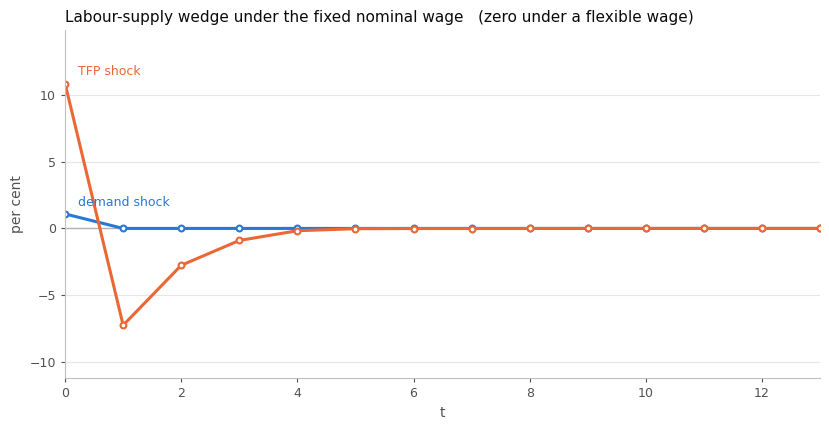

In [7]:
def wedge(a):
    return np.log(a['omega']) - (np.log(chi) + eta * np.log(a['L']) + gamma * np.log(a['Y']))

wt = pd.DataFrame({f'{nm} ({lab})': 100 * wedge(d[nm])
                   for lab, d in [('fixed', FIX), ('flex', FLEX)] for nm in SHOCKS},
                  index=pd.Index(range(T), name='t')).iloc[:8]
with pd.option_context('display.float_format', '{:,.4f}'.format):
    display(wt)
print('flexible-wage columns are zero by construction:  max |wedge| = '
      f'{max(np.max(np.abs(wedge(FLEX[nm]))) for nm in SHOCKS):.2e}')

fig, ax = plt.subplots(figsize=(8.4, 4.4))
fig.patch.set_facecolor('white'); style(ax)
for nm, col in zip(SHOCKS, [BLUE, ORANGE]):
    v = 100 * wedge(FIX[nm])[:H]
    ax.plot(t, v, color=col, lw=2.2, marker='o', ms=4.2, mfc='white', mec=col, mew=1.5)
    j = int(np.argmax(np.abs(v)))
    ax.annotate(nm, xy=(j, v[j]), xytext=(9, 6 if v[j] >= 0 else -14),
                textcoords='offset points', fontsize=9, color=col)
ax.margins(y=0.22)
ax.set_ylabel('per cent', color=MUTED)
ax.set_title('Labour-supply wedge under the fixed nominal wage   '
             '(zero under a flexible wage)', color=INK, fontsize=11, loc='left')
fig.tight_layout()
fig.savefig('../ss_fixed_wage_wedge.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()

## 6. Optimal interest-rate policy

Section 4 established that the rate is not neutral here, so the question has content.  The
objective is the household's own utility, which `solve` already returns:

$$U=\sum_t\beta^t\Xi_t\Bigl[\frac{C_t^{1-\gamma}}{1-\gamma}-\chi\frac{L_t^{1+\eta}}{1+\eta}\Bigr].$$

The caveat at the end of this notebook says utility is not comparable *across* wage
assumptions, because the household is rationed under a fixed wage and on its supply curve
under a flexible one.  That does not bar the comparison made here: every path below is the
same rationed household in the same fixed-wage economy, differing only in the rate path, so
$U$ ranks them like for like.  The flexible-wage numbers appear only as a reference line and
are never used to pick a policy.

### Is there a level channel?

Before optimising, run a uniform rate with **no shock at all**.  If the rate only mattered for
stabilisation this table peaks at $\rho$ and falls away on both sides.  It does: firms price at
marginal cost ($\mu=1$), so the steady state is efficient and there is nothing for a permanent
rate deviation to correct.  $\max_i U$ with no shock returns $i_t=\rho$ to five decimals.

| | value |
|---|---|
| removing the wage friction, demand shock (flex $-$ fixed, both at $\rho$) | $+0.0000020$ |
| removing the wage friction, TFP shock | $+0.000313$ |
| moving the rate level, uniform $i=\rho-0.5$pp, no shock | $-0.011859$ |
| moving the rate level, uniform $i=\rho+0.5$pp, no shock | $-0.010310$ |

Both level moves are *losses*, so the optimiser has no reason to make them.

This is worth checking explicitly because it fails under a markup.  With
$\mu=\sigma/(\sigma-1)=1.25$ the steady state is inefficient — employment is too low — and the
rate becomes a second-best instrument against *that* rather than against the shock: the
no-shock optimum then engineers a permanent $3\%$ output boom, hits the zero bound in 5 of 8
free periods, and delivers $+0.091\%$ of steady-state consumption with no shock present,
against $+0.002\%$ for the entire demand-shock stabilisation problem.

The optimum is still solved **three times** — once with no shock, once per shock — but the
no-shock solve is now a *check* rather than a correction to be netted out.  The shock response

$$\text{stabilisation}_t=i^{*}_t(\text{shock})-i^{*}_t(\text{no shock})$$

is therefore just $i^{*}_t(\text{shock})-\rho$.

### What is not attainable

Policy cannot simply reproduce the flexible-wage allocation.  A $\tau$-cohort delivering at
$t$ prices off $W_s\prod_{j=s}^{t-1}(1+i_j)$ with $s=t-\tau$, so matching the flexible-wage
price requires

$$\prod_{j=s}^{t-1}(1+i_j)\big/(1+\rho)^{t-s}=W^{\text{flex}}_s/W^{ss}
\qquad\text{for every }(s,t)\text{ pair.}$$

The left-hand side depends on both dates, the right-hand side only on $s$.  Once several
$\tau$-cohorts share a delivery date the system is overdetermined, so the optimum below is a
genuine trade-off rather than a targeting rule that hits its target.

In [8]:
from scipy.optimize import minimize

I_LO, I_HI = 0.0, 0.05
L_GRID     = [4, 8]
SEEDS      = [lambda L: np.full(L, rho), lambda L: np.full(L, 0.005)]
OPT_CASES  = {'no shock': {}, **SHOCKS}


def u_parts(s):
    """(U_consumption, U_labour) so a consumption-equivalent metric can be formed."""
    w = DISC * np.exp(s['xi'])
    return (float(np.sum(w * s['Y'] ** (1 - gamma) / (1 - gamma))),
            float(np.sum(w * chi * s['L'] ** (1 + eta) / (1 + eta))))


def cons_equiv(U_alt, s_base):
    """Permanent proportional change in C worth U_alt - U(s_base), in the fixed-wage economy."""
    UC, UN = u_parts(s_base)
    return float(((U_alt + UN) / UC) ** (1.0 / (1.0 - gamma)) - 1.0)


def full_path(ip):
    """L free periods, then the peg."""
    return np.r_[np.asarray(ip, float), np.full(T - len(ip), rho)]


def neg_U(ip, kw, key=None):
    """Objective.  Rate paths that break the committed-goods floor are penalised, not crashed.

    `key` is accepted but deliberately NOT handed to `solve`.  `solve` caches its converged
    guess under the key and warm-starts the next call from it, so a key shared across the
    optimiser's evaluations makes this objective depend on the ORDER they happen in:
    re-evaluated at its own seed it can fail the inner root-find and return the 1e3
    penalty, which stalls the line search at iteration 0 and hands back the seed while
    reporting success.  key=None starts every evaluation from the same guess.
    """
    s = solve(full_path(ip), phi=1.0, key=None, **kw)
    if not s['ok'] or not np.isfinite(s['welfare']):
        return 1e3
    return -s['welfare']


def optimise(kw, L, key, seeds=SEEDS):
    best = None
    for sd in seeds:
        r = minimize(neg_U, sd(L), args=(kw, key), method='L-BFGS-B',
                     bounds=[(I_LO, I_HI)] * L,
                     options={'maxiter': 2000, 'ftol': 1e-16, 'gtol': 1e-12})
        if best is None or r.fun < best.fun:
            best = r
    return best


# --- the level channel, with no shock at all -------------------------------------------
print('THE LEVEL CHANNEL: uniform rate for the whole horizon, NO SHOCK')
print(f'   {"uniform i":>10}{"U":>18}{"Y_0 %":>10}{"L_0 %":>10}{"W/P_0 %":>10}{"wedge_0 %":>11}')
print('   ' + '-' * 69)
for lv in [0.0, 0.005, rho, 0.015, 0.02]:
    s = solve(np.full(T, lv), phi=1.0, key='lvl')
    print(f'   {lv:>10.4f}{s["welfare"]:>18.9f}'
          f'{100 * np.log(s["Y"][0] / SS["Y"]):>10.4f}'
          f'{100 * np.log(s["L"][0] / SS["L"]):>10.4f}'
          f'{100 * np.log(s["omega"][0] / SS["omega"]):>10.4f}'
          f'{100 * wedge(s)[0]:>11.4f}')
print('   -> peaks at rho and falls away on both sides: no level channel, which is what\n'
      '      price = marginal cost should give.  At mu = sigma/(sigma-1) it peaks BELOW rho.\n')

# --- solve the three optima -------------------------------------------------------------
OPT = {}
print('OPTIMISING  (L free periods, then the peg at rho)')
print(f'   {"case":<14}{"L":>3}{"U":>18}{"at bounds":>11}   i*[:8]')
print('   ' + '-' * 96)
for nm, kw in OPT_CASES.items():
    for L in L_GRID:
        b = optimise(kw, L, f'opt{nm}')
        OPT[(nm, L)] = b
        nb_lo = int(np.sum(np.isclose(b.x, I_LO))); nb_hi = int(np.sum(np.isclose(b.x, I_HI)))
        print(f'   {nm:<14}{L:>3}{-b.fun:>18.9f}{f"{nb_lo}lo/{nb_hi}hi":>11}   '
              f'{np.round(b.x[:8], 5)}')
print()

THE LEVEL CHANNEL: uniform rate for the whole horizon, NO SHOCK
    uniform i                 U     Y_0 %     L_0 %   W/P_0 %  wedge_0 %
   ---------------------------------------------------------------------
       0.0000      -2.947346190    2.1483   29.4200  -25.5544   -88.6910
       0.0050      -2.907691052    0.8367   14.6873  -13.2150   -44.2630
       0.0100      -2.895831827   -0.0000    0.0000    0.0000     0.0000


       0.0150      -2.906142155   -0.5068  -14.7320   13.8012    44.2789
       0.0200      -2.934661445   -0.8032  -29.5681   27.9506    88.6930
   -> peaks at rho and falls away on both sides: no level channel, which is what
      price = marginal cost should give.  At mu = sigma/(sigma-1) it peaks BELOW rho.

OPTIMISING  (L free periods, then the peg at rho)
   case            L                 U  at bounds   i*[:8]
   ------------------------------------------------------------------------------------------------


   no shock        4      -2.895831827    0lo/0hi   [0.01 0.01 0.01 0.01]


   no shock        8      -2.895831827    0lo/0hi   [0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01]


   demand shock    4      -2.894724656    0lo/0hi   [0.00872 0.0097  0.00979 0.00981]


   demand shock    8      -2.894724635    0lo/0hi   [0.00875 0.00972 0.0098  0.00986 0.00991 0.00994 0.00996 0.00997]


   TFP shock       4      -2.898382354    1lo/0hi   [0.      0.01023 0.01163 0.01087]


   TFP shock       8      -2.898382223    1lo/0hi   [0.      0.01026 0.01167 0.01085 0.01025 0.00999 0.00987 0.00975]



### The optimal path, and the part of it that is a shock response

In [9]:
L_USE = L_GRID[-1]
W = 44
SUMM = {}
for nm, kw in OPT_CASES.items():
    b      = OPT[(nm, L_USE)]
    s_opt  = solve(full_path(b.x), phi=1.0, key=f'r{nm}', **kw)
    s_peg  = solve(np.full(T, rho), phi=1.0, key=f'p{nm}', **kw)
    s_flex = solve(np.full(T, rho), phi=0.0, key=f'f{nm}', **kw)
    SUMM[nm] = (b.x, s_opt, s_peg, s_flex)
    print('=' * 84); print(nm); print('=' * 84)
    print(f'   {"U, rate pegged at rho":<{W}}: {s_peg["welfare"]:.9f}')
    print(f'   {"U, optimal rate":<{W}}: {s_opt["welfare"]:.9f}')
    print(f'   {"welfare gain (consumption equivalent)":<{W}}: '
          f'{100 * cons_equiv(s_opt["welfare"], s_peg):+.6f}% of ss C')
    print(f'   {"U, flexible wage at rho (reference only)":<{W}}: {s_flex["welfare"]:.9f}')
    print(f'   {"optimal rate path i*[:8]":<{W}}: {np.round(b.x[:8], 5)}')
    print(f'   {"peak |Y|, peg / optimal %":<{W}}: '
          f'{100 * np.max(np.abs(np.log(s_peg["Y"] / SS["Y"]))):.4f}'
          f' / {100 * np.max(np.abs(np.log(s_opt["Y"] / SS["Y"]))):.4f}')
    print(f'   {"peak |L|, peg / optimal %":<{W}}: '
          f'{100 * np.max(np.abs(np.log(s_peg["L"] / SS["L"]))):.4f}'
          f' / {100 * np.max(np.abs(np.log(s_opt["L"] / SS["L"]))):.4f}')
    print(f'   {"peak |wedge|, peg / optimal %":<{W}}: '
          f'{100 * np.max(np.abs(wedge(s_peg))):.4f}'
          f' / {100 * np.max(np.abs(wedge(s_opt))):.4f}')
    print()

# --- the stabilisation component --------------------------------------------------------
print('=' * 84)
print('STABILISATION COMPONENT   i*(shock) - i*(no shock),  percentage points')
print('=' * 84)
base = OPT[('no shock', L_USE)].x
print(f'   {"level benchmark i*(no shock)":<30}' + ''.join(f'{100*v:>9.4f}' for v in base))
for nm in SHOCKS:
    d = OPT[(nm, L_USE)].x - base
    print(f'   {nm:<30}' + ''.join(f'{100*v:>9.4f}' for v in d))
print('\n   the level benchmark is what the rate would do with no shock at all; the rows')
print('   beneath it are the genuine response to each shock.')

no shock
   U, rate pegged at rho                       : -2.895831827
   U, optimal rate                             : -2.895831827
   welfare gain (consumption equivalent)       : -0.000000% of ss C
   U, flexible wage at rho (reference only)    : -2.895831827
   optimal rate path i*[:8]                    : [0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01]
   peak |Y|, peg / optimal %                   : 0.0000 / 0.0000
   peak |L|, peg / optimal %                   : 0.0000 / 0.0000
   peak |wedge|, peg / optimal %               : 0.0000 / 0.0000



demand shock
   U, rate pegged at rho                       : -2.894726586
   U, optimal rate                             : -2.894724635
   welfare gain (consumption equivalent)       : +0.000089% of ss C
   U, flexible wage at rho (reference only)    : -2.894724634
   optimal rate path i*[:8]                    : [0.00875 0.00972 0.0098  0.00986 0.00991 0.00994 0.00996 0.00997]
   peak |Y|, peg / optimal %                   : 0.0430 / 0.0789
   peak |L|, peg / optimal %                   : 0.0437 / 0.3955
   peak |wedge|, peg / optimal %               : 1.0875 / 0.0192

TFP shock
   U, rate pegged at rho                       : -2.898616824
   U, optimal rate                             : -2.898382223
   welfare gain (consumption equivalent)       : +0.010733% of ss C
   U, flexible wage at rho (reference only)    : -2.898303510
   optimal rate path i*[:8]                    : [0.      0.01026 0.01167 0.01085 0.01025 0.00999 0.00987 0.00975]
   peak |Y|, peg / optimal %               

wrote /Users/samuelzhao/Documents/GitHub/shocky_shocks/ss_fixed_wage_cohorts.png


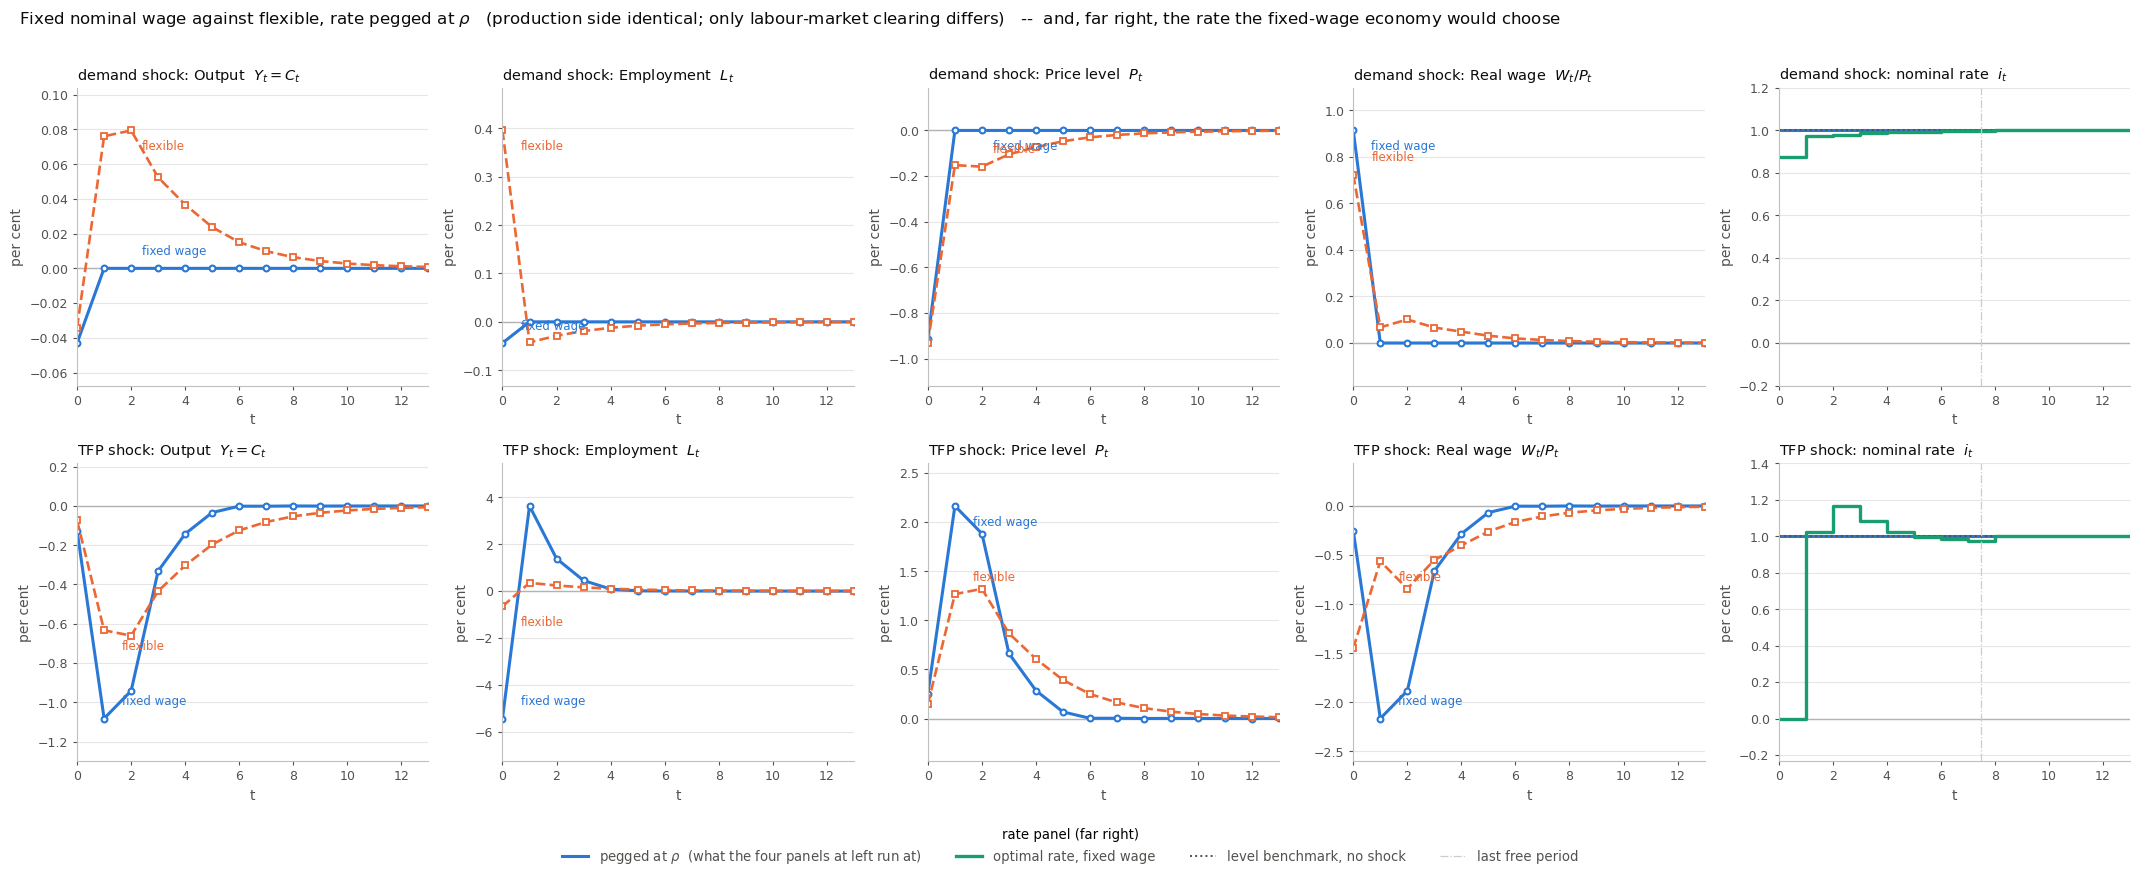

In [10]:
cohorts_figure()

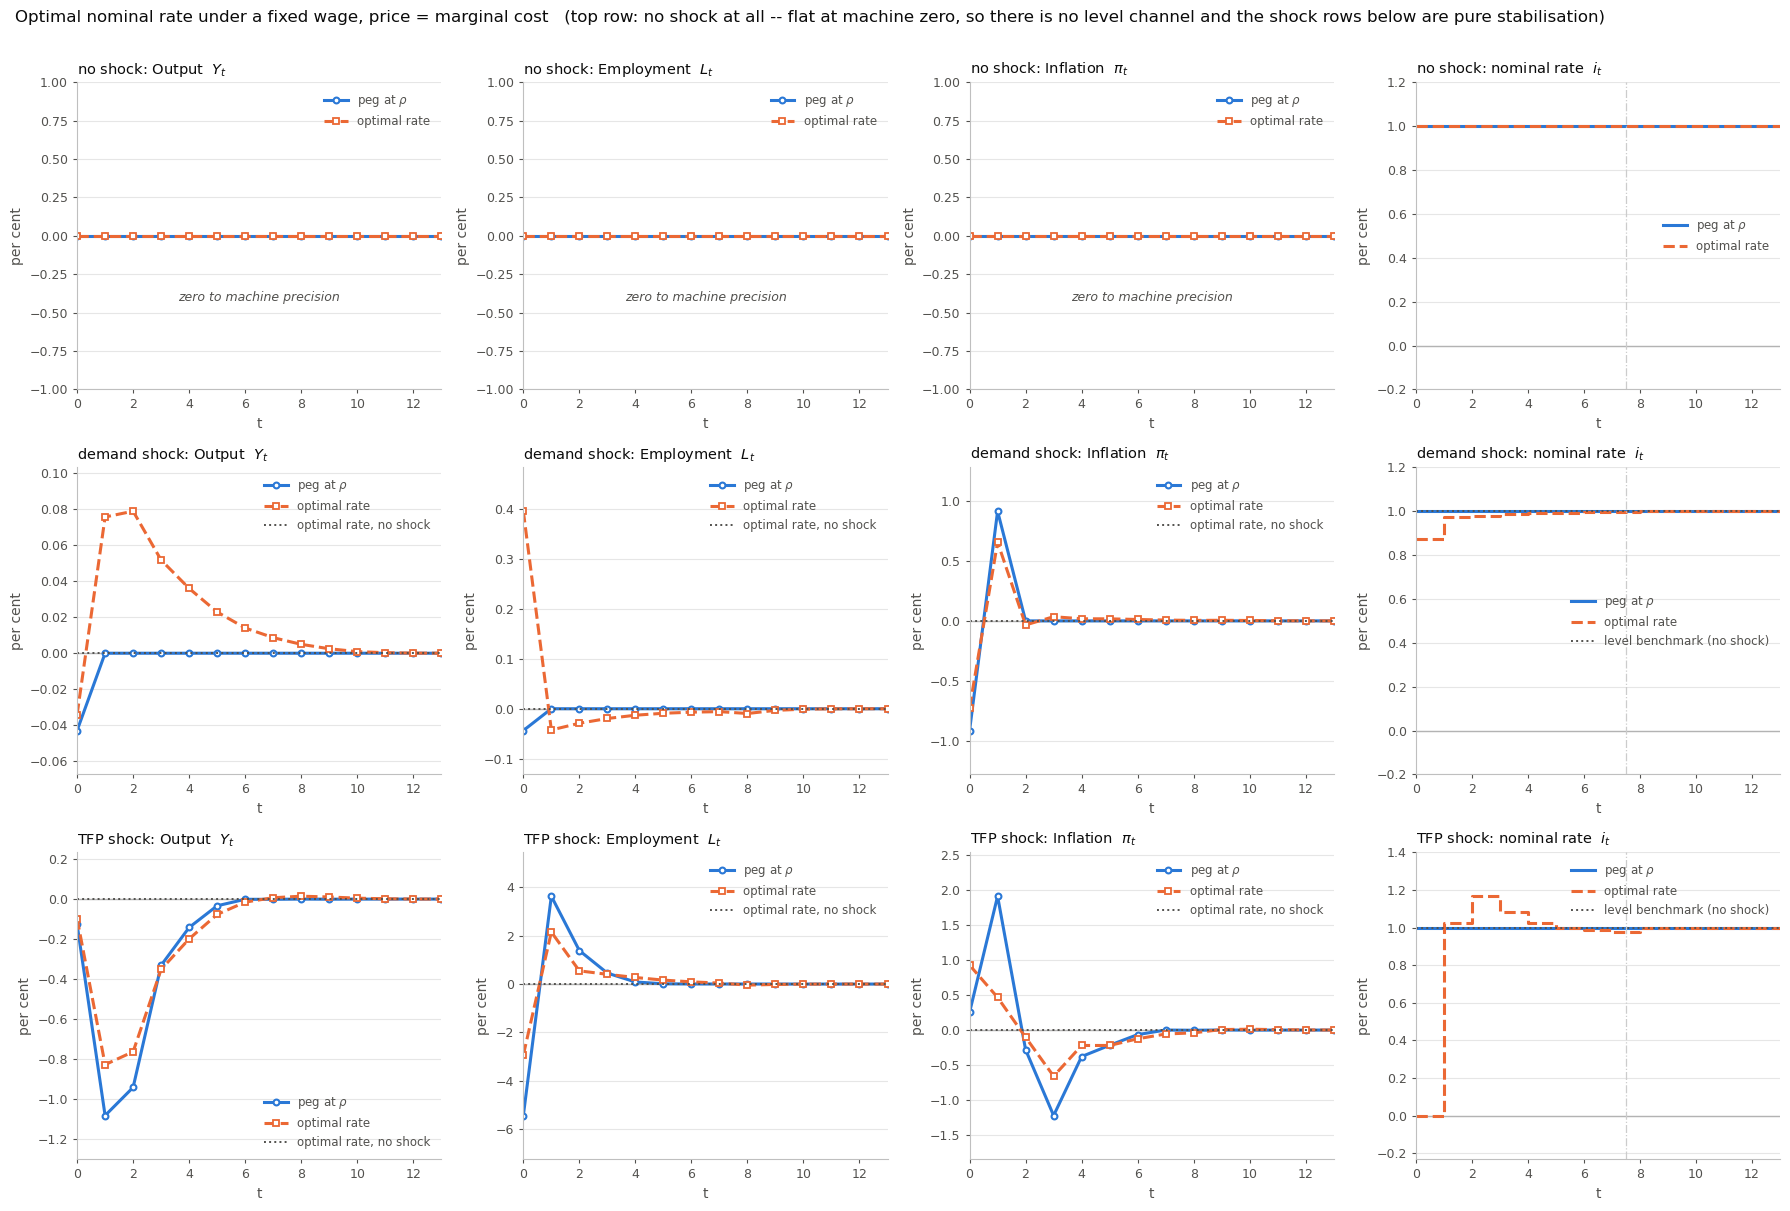

                peak |Y| opt  peak |Y| vs no-shock opt   welfare gain  gain over no-shock opt
---------------------------------------------------------------------------------------------
no shock             0.0000%                   0.0000%       -0.0000%                      --
demand shock         0.0789%                   0.0789%        0.0001%                 0.0001%
TFP shock            0.8279%                   0.8279%        0.0107%                 0.0107%


In [11]:
# Three rows, not two: the top one has NO SHOCK at all.  At mu = 1 it comes out flat at
# machine zero -- the check that there is no level channel, so the shock rows below are pure
# stabilisation and can be read against zero.  Under a markup this row is NOT flat (a ~3%
# output boom with no shock present), which is why it is drawn rather than assumed.
# inflation is already a log difference (pi[0] is measured against the steady-state P),
# so it is plotted as it comes rather than differenced against SS like the level panels
ROWS  = list(OPT_CASES)                       # 'no shock' first, then the two shocks
PAN_O = [('Output  $Y_t$',       lambda s: 100 * np.log(s['Y'] / SS['Y'])),
         ('Employment  $L_t$',   lambda s: 100 * np.log(s['L'] / SS['L'])),
         ('Inflation  $\pi_t$',  lambda s: 100 * s['pi'])]

fig, axes = plt.subplots(len(ROWS), 4, figsize=(18, 4 * len(ROWS)))
fig.patch.set_facecolor('white')
s_ns = SUMM['no shock'][1]                    # the no-shock optimal allocation

for row, nm in enumerate(ROWS):
    _, s_opt, s_peg, s_flex = SUMM[nm]
    for col, (name, series) in enumerate(PAN_O):
        ax = axes[row, col]; style(ax)
        ax.plot(t, series(s_peg)[:H], color=BLUE, lw=2.2,
                marker='o', ms=4.2, mfc='white', mec=BLUE, mew=1.5, label=r'peg at $\rho$')
        ax.plot(t, series(s_opt)[:H], color=ORANGE, lw=2.2, ls='--',
                marker='s', ms=4, mfc='white', mec=ORANGE, mew=1.3, label='optimal rate')
        if nm != 'no shock':
            ax.plot(t, series(s_ns)[:H], color=MUTED, lw=1.4, ls=':',
                    label='optimal rate, no shock')
        # a panel that is numerically zero must LOOK zero: without this matplotlib
        # autoscales onto the root-finder's float noise (~1e-14 per cent) and draws a
        # wiggle that reads as a response.
        if max(np.max(np.abs(series(v)[:H])) for v in (s_peg, s_opt)) < 1e-8:
            ax.set_ylim(-1, 1)
            ax.annotate('zero to machine precision', xy=(0.5, 0.30), xycoords='axes fraction',
                        ha='center', va='center', fontsize=9, color=MUTED, style='italic')
        else:
            ax.margins(y=0.20)
        ax.set_ylabel('per cent', color=MUTED)
        ax.set_title(f'{nm}: {name}', color=INK, fontsize=10.5, loc='left')
        ax.legend(frameon=False, fontsize=8.5, labelcolor=MUTED)

    ax = axes[row, 3]; style(ax)
    ip_opt = full_path(SUMM[nm][0])
    ax.step(t, 100 * np.full(H, rho), where='post', color=BLUE, lw=2.2, label=r'peg at $\rho$')
    ax.step(t, 100 * ip_opt[:H], where='post', color=ORANGE, lw=2.2, ls='--',
            label='optimal rate')
    if nm != 'no shock':
        ax.step(t, 100 * full_path(OPT[('no shock', L_USE)].x)[:H], where='post', color=MUTED,
                lw=1.4, ls=':', label='level benchmark (no shock)')
    ax.axvline(L_USE - 0.5, color='0.8', lw=0.9, ls='-.')
    ax.margins(y=0.20); ax.set_ylabel('per cent', color=MUTED)
    ax.set_title(f'{nm}: nominal rate  $i_t$', color=INK, fontsize=10.5, loc='left')
    ax.legend(frameon=False, fontsize=8.5, labelcolor=MUTED)

fig.suptitle('Optimal nominal rate under a fixed wage, price = marginal cost   (top row: no '
             'shock at all -- flat at machine zero, so there is no level channel and the '
             'shock rows below are pure stabilisation)',
             fontsize=12, color=INK, x=0.011, ha='left', y=1.005)
fig.tight_layout()
fig.savefig('../ss_fixed_wage_optimal_rate.png', dpi=200, bbox_inches='tight',
            facecolor='white')
plt.show()

# how much of the swing is the level channel?
print(f'{"":<14}{"peak |Y| opt":>14}{"peak |Y| vs no-shock opt":>26}'
      f'{"welfare gain":>15}{"gain over no-shock opt":>24}')
print('-' * 93)
g_ns = cons_equiv(SUMM['no shock'][1]['welfare'], SUMM['no shock'][2])
for nm in ROWS:
    _, s_o, s_p, _ = SUMM[nm]
    pk  = 100 * np.max(np.abs(np.log(s_o['Y'] / SS['Y'])))
    pkd = 100 * np.max(np.abs(np.log(s_o['Y'] / s_ns['Y'])))
    g   = 100 * cons_equiv(s_o['welfare'], s_p)
    print(f'{nm:<14}{pk:>13.4f}%{pkd:>25.4f}%{g:>14.4f}%'
          + (f'{g - 100 * g_ns:>23.4f}%' if nm != 'no shock' else f'{"--":>24}'))


## Caveats

* The wage is fixed at its steady-state level for the whole horizon — no partial adjustment, no
  indexation, no re-set date.  `phi` interpolates the two extremes but nothing in between is
  a microfounded contract.
* The household is rationed in the labour market, so its first-order condition for labour does
  not hold.  Welfare comparisons across the two wage assumptions are therefore not
  like-for-like, and the utility numbers should not be read as a ranking of the two economies.
* Everything else is inherited from the cohort notebooks: $\Delta_i$ held at its steady-state
  value, "unexpected" meaning only that dates before 0 were not conditioned on the shock, and
  the demand shock entering the Euler equation alone.
* Firms price at marginal cost, $\mu=1$. This matters for section 6 and not only for the
  steady-state levels: under a markup the steady state is inefficient, and because the nominal
  wage is pinned for the whole horizon with no re-set date, the rate moves $W/P$ one for one
  against that inefficiency. The optimum is then dominated by a permanent *level* channel — a
  boom engineered with no shock present — rather than by stabilisation. The level benchmark and
  the stabilisation component are reported separately so that this stays visible either way; at
  $\mu=1$ the no-shock optimum is $\rho$ and the two coincide.
* The optimum is taken over the first `L_USE` periods with the rate pegged at $\rho$
  afterwards. It is a constrained optimum in that sense, not the unrestricted first best.
